# Premier League 2024–2025 — tái lập kết quả đã khóa

Notebook đọc lại artifact của vòng test `final_test_v1`, tự tính lại metric và đối chiếu. **Không fit mô hình, không chọn lại calibration hoặc tune theo test.** P/F là proxy lịch sử cầu thủ; chưa có announced XI T−60 được xác minh.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if not (ROOT / 'research/final_lock.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'research/final_lock.json').exists(), 'Mở notebook từ thư mục dự án hoặc notebooks/'
sys.path.insert(0, str(ROOT / 'scripts'))
from delivery_data import load_delivery, FAMILY, ARM
data = load_delivery(ROOT)
print('Đã xác minh khóa, 380 trận và 11.400 bộ xác suất. Không huấn luyện lại.')

Đã xác minh khóa, 380 trận và 11.400 bộ xác suất. Không huấn luyện lại.


## 1. Dữ liệu và phạm vi

A_full train 2015–2023 với 3.040 trận; cohort common train 2019–2023 với 1.520 trận. Validation 2023–2024 và test 2024–2025 có 380 trận mỗi mùa. P/F reset đầu mùa; snapshot chỉ dùng ngày lịch trước. Availability vẫn là giả định nửa đêm kế tiếp, chưa phải publication timestamp đã chứng minh.

In [2]:
pd.DataFrame([{'Nhánh':'A_full','Train':3040,'Validation':380,'Test':380,'Đặc trưng':40},
 {'Nhánh':'A_common','Train':1520,'Validation':380,'Test':380,'Đặc trưng':40},
 {'Nhánh':'A+P','Train':1520,'Validation':380,'Test':380,'Đặc trưng':52},
 {'Nhánh':'A+P+F','Train':1520,'Validation':380,'Test':380,'Đặc trưng':60}])

,Nhánh,Train,Validation,Test,Đặc trưng
0,A_full,3040,380,380,40
1,A_common,1520,380,380,40
2,A+P,1520,380,380,52
3,A+P+F,1520,380,380,60


## 2. Những phát hiện audit quan trọng

59 placeholder của trận bị hoãn được loại có quy tắc và bằng chứng; 136 trận đầu mùa 2022–2023 có starts/xG/xA toàn 0 nên được đánh dấu không dùng được. Không đưa xG/xA hay starts vào P/F. 322 dòng Assistant Manager mùa test bị loại. Bảng sau mô tả độ phủ, không phải đánh giá mô hình.

In [3]:
audit = json.loads((ROOT/'reports/player_history/audit.json').read_text(encoding='utf-8'))
pd.DataFrame([{k:s.get(k) for k in ['season','raw_rows','status','curated_rows','linked_fixtures']} for s in audit['seasons']])

,season,raw_rows,status,curated_rows,linked_fixtures
0,2016-17,23679,not_normalized_missing_fixture_or_team_mapping...,NaN,NaN
1,2017-18,22467,not_normalized_missing_fixture_or_team_mapping...,NaN,NaN
2,2018-19,21790,not_normalized_missing_fixture_or_team_mapping...,NaN,NaN
3,2019-20,22560,normalized_and_linked,22501.0,380.0
4,2020-21,24365,normalized_and_linked,24365.0,380.0
5,2021-22,25447,normalized_and_linked,25447.0,380.0
6,2022-23,26505,normalized_and_linked,26505.0,380.0
7,2023-24,29725,normalized_and_linked,29725.0,380.0


## 3. Tự tính lại metric

Thứ tự xác suất luôn H, D, A. Log Loss dùng xác suất của nhãn đúng; Brier là tổng sai số bình phương ba lớp rồi lấy trung bình, miền [0,2]. Precision/recall bằng 0 khi mẫu số bằng 0, phù hợp protocol.

In [4]:
pred = pd.DataFrame(data['predictions'])
labels = ['H','D','A']
checks = []
for (model, variant), group in pred.groupby(['model','variant']):
    p = group[['p_H','p_D','p_A']].to_numpy(float)
    y = np.array([labels.index(v) for v in group['result']])
    yh = p.argmax(axis=1)
    assert len(group)==380 and group.match_id.nunique()==380
    np.testing.assert_allclose(p.sum(axis=1),1,atol=1e-10)
    ll = -np.log(np.clip(p[np.arange(len(y)),y],1e-15,1)).mean()
    brier = ((p-np.eye(3)[y])**2).sum(axis=1).mean()
    f1=[]
    for c in range(3):
        tp=((y==c)&(yh==c)).sum(); fp=((y!=c)&(yh==c)).sum(); fn=((y==c)&(yh!=c)).sum()
        f1.append(2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.)
    metric={'accuracy':(yh==y).mean(),'macro_f1':np.mean(f1),'log_loss':ll,'brier_sum':brier}
    expected=data['result']['metrics'][model+'::'+variant]
    for k,v in metric.items(): np.testing.assert_allclose(v,expected[k],atol=1e-12,rtol=0)
    checks.append({'model':model,'variant':variant,**metric})
metrics = pd.DataFrame(checks)
print(f'Tái tính đúng {len(metrics)} đầu ra xác suất trên cùng 380 trận.')
metrics.head()

Tái tính đúng 30 đầu ra xác suất trên cùng 380 trận.


,model,variant,accuracy,macro_f1,log_loss,brier_sum
0,common__elo,raw,0.544737,0.411228,0.980248,0.585381
1,common__elo,temperature,0.544737,0.411228,0.984701,0.588865
2,common__frequency,raw,0.407895,0.193146,1.079199,0.654244
3,common__logistic__A_common,raw,0.531579,0.404303,0.994297,0.593678
4,common__logistic__A_common,temperature,0.531579,0.404303,0.998691,0.596304


## 4. Kết quả tham chiếu đã chọn trước test

Elo A_full là tham chiếu đã chỉ định ở protocol, không chọn lại mô hình theo điểm test.

In [5]:
reference = metrics[metrics.model.eq('full__elo')].copy()
reference[['variant','accuracy','macro_f1','log_loss','brier_sum']]

,variant,accuracy,macro_f1,log_loss,brier_sum
21,raw,0.547368,0.410958,0.981412,0.586540
22,temperature,0.547368,0.410958,0.986060,0.589928


## 5. Calibration ngoài mẫu

Temperature được fit trên validation 2023–2024. Điểm validation sau fit là in-sample diagnostics. Bảng dưới kiểm tra tác động lên test, giữ cả raw và temperature.

In [6]:
calibration = metrics.pivot(index='model',columns='variant',values='log_loss').dropna()
calibration['delta_temperature_minus_raw'] = calibration['temperature']-calibration['raw']
assert (calibration.delta_temperature_minus_raw > 0).all()
print('Cả 14 mô hình có Log Loss test tăng sau temperature trong thí nghiệm này.')
calibration

Cả 14 mô hình có Log Loss test tăng sau temperature trong thí nghiệm này.


variant,raw,temperature,delta_temperature_minus_raw
model,,,
common__elo,0.980248,0.984701,0.004453
common__logistic__A_common,0.994297,0.998691,0.004395
common__logistic__A_plus_P,0.996879,1.001071,0.004193
common__logistic__A_plus_P_plus_F,0.995569,0.996880,0.001311
common__random_forest__A_common,0.999784,1.004754,0.004970
common__random_forest__A_plus_P,1.001184,1.005990,0.004806
common__random_forest__A_plus_P_plus_F,0.998710,1.002274,0.003564
common__xgboost__A_common,1.001047,1.006829,0.005782
common__xgboost__A_plus_P,1.002468,1.008764,0.006296


## 6. So sánh P và F trên cùng cohort

Đọc các khoảng bootstrap đã đăng ký và đã tính trong vòng test. Block chính 2 tuần; family interval 99,1667% cho sáu contrast temperature. Không resample thêm hoặc chọn block sau khi thấy test.

In [7]:
contrasts = pd.DataFrame(data['result']['paired_feature_comparisons'])
primary = contrasts[contrasts.variant.eq('temperature') & contrasts.block_weeks.eq(2)]
assert len(primary)==6
assert ((primary.family_ci_low<=0)&(primary.family_ci_high>=0)).all()
primary[['family','model_arm','reference_arm','delta_log_loss','ci95_low','ci95_high','family_ci_low','family_ci_high']]

,family,model_arm,reference_arm,delta_log_loss,ci95_low,ci95_high,family_ci_low,family_ci_high
19,logistic,A_plus_P,A_common,0.002380,-0.005542,0.010632,-0.008593,0.012916
22,random_forest,A_plus_P,A_common,0.001236,-0.004388,0.006273,-0.006951,0.007763
25,xgboost,A_plus_P,A_common,0.001935,-0.002191,0.006491,-0.003619,0.008098
28,logistic,A_plus_P_plus_F,A_plus_P,-0.004191,-0.013147,0.003810,-0.016532,0.006862
31,random_forest,A_plus_P_plus_F,A_plus_P,-0.003716,-0.008607,0.000992,-0.010004,0.002388
34,xgboost,A_plus_P_plus_F,A_plus_P,-0.003716,-0.009766,0.002610,-0.011693,0.005211


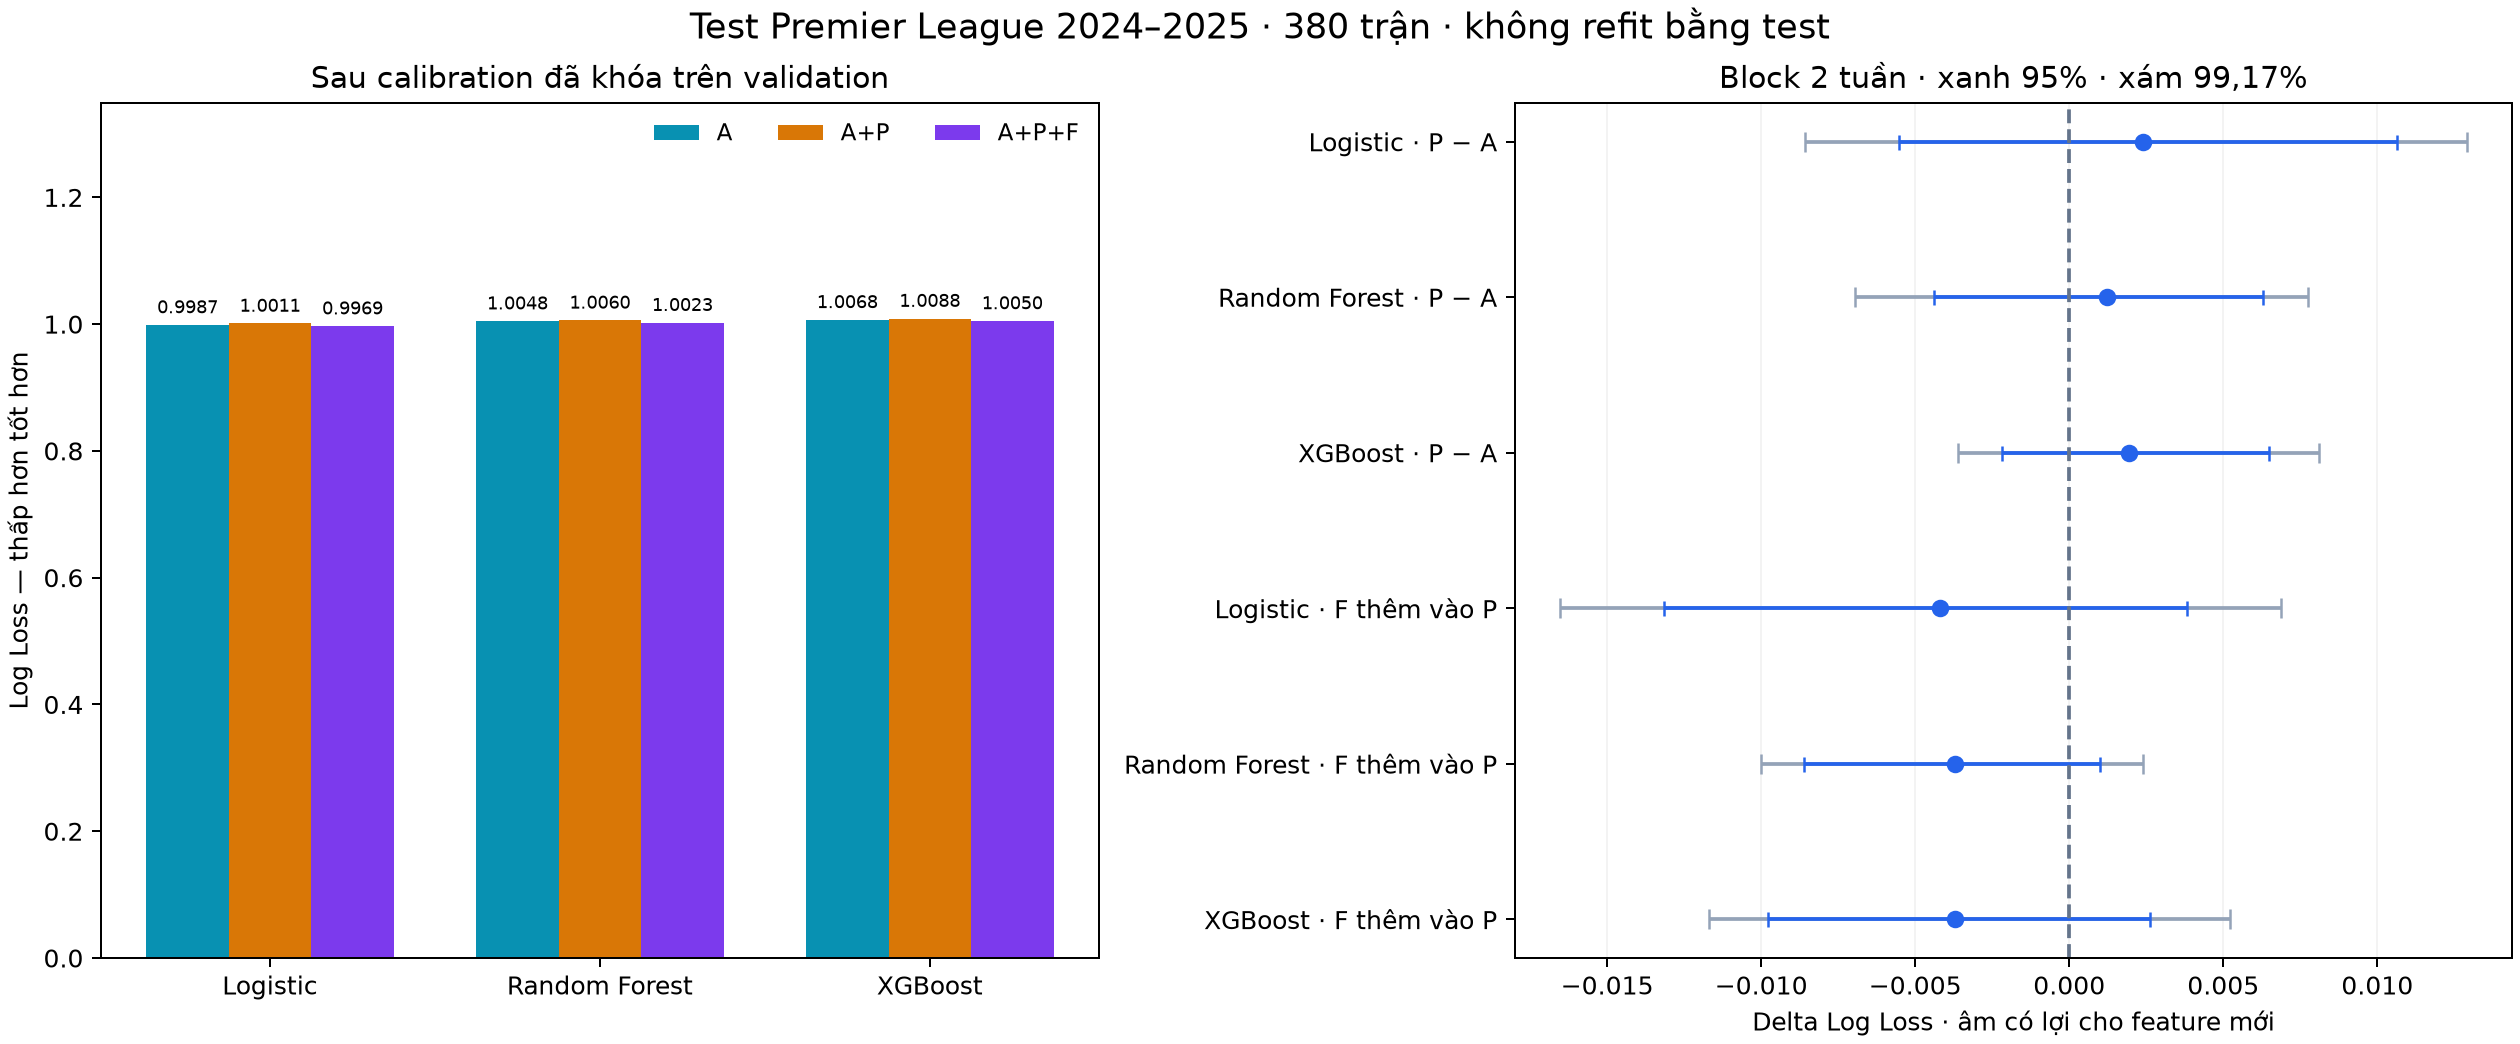

In [8]:
display(Image(filename=str(ROOT/'reports/final_test_v1/feature_comparison.png')))

## 7. Điểm yếu lớp hòa và reliability

Accuracy không thay thế đánh giá từng lớp. Temperature dương giữ nguyên argmax, vì vậy không tự cải thiện recall lớp D.

,Dự đoán H,Dự đoán D,Dự đoán A
Thật H,131,0,24
Thật D,61,0,32
Thật A,55,0,77


,precision,recall,f1,support
H,0.530364,0.845161,0.651741,155.0
D,0.000000,0.000000,0.000000,93.0
A,0.578947,0.583333,0.581132,132.0


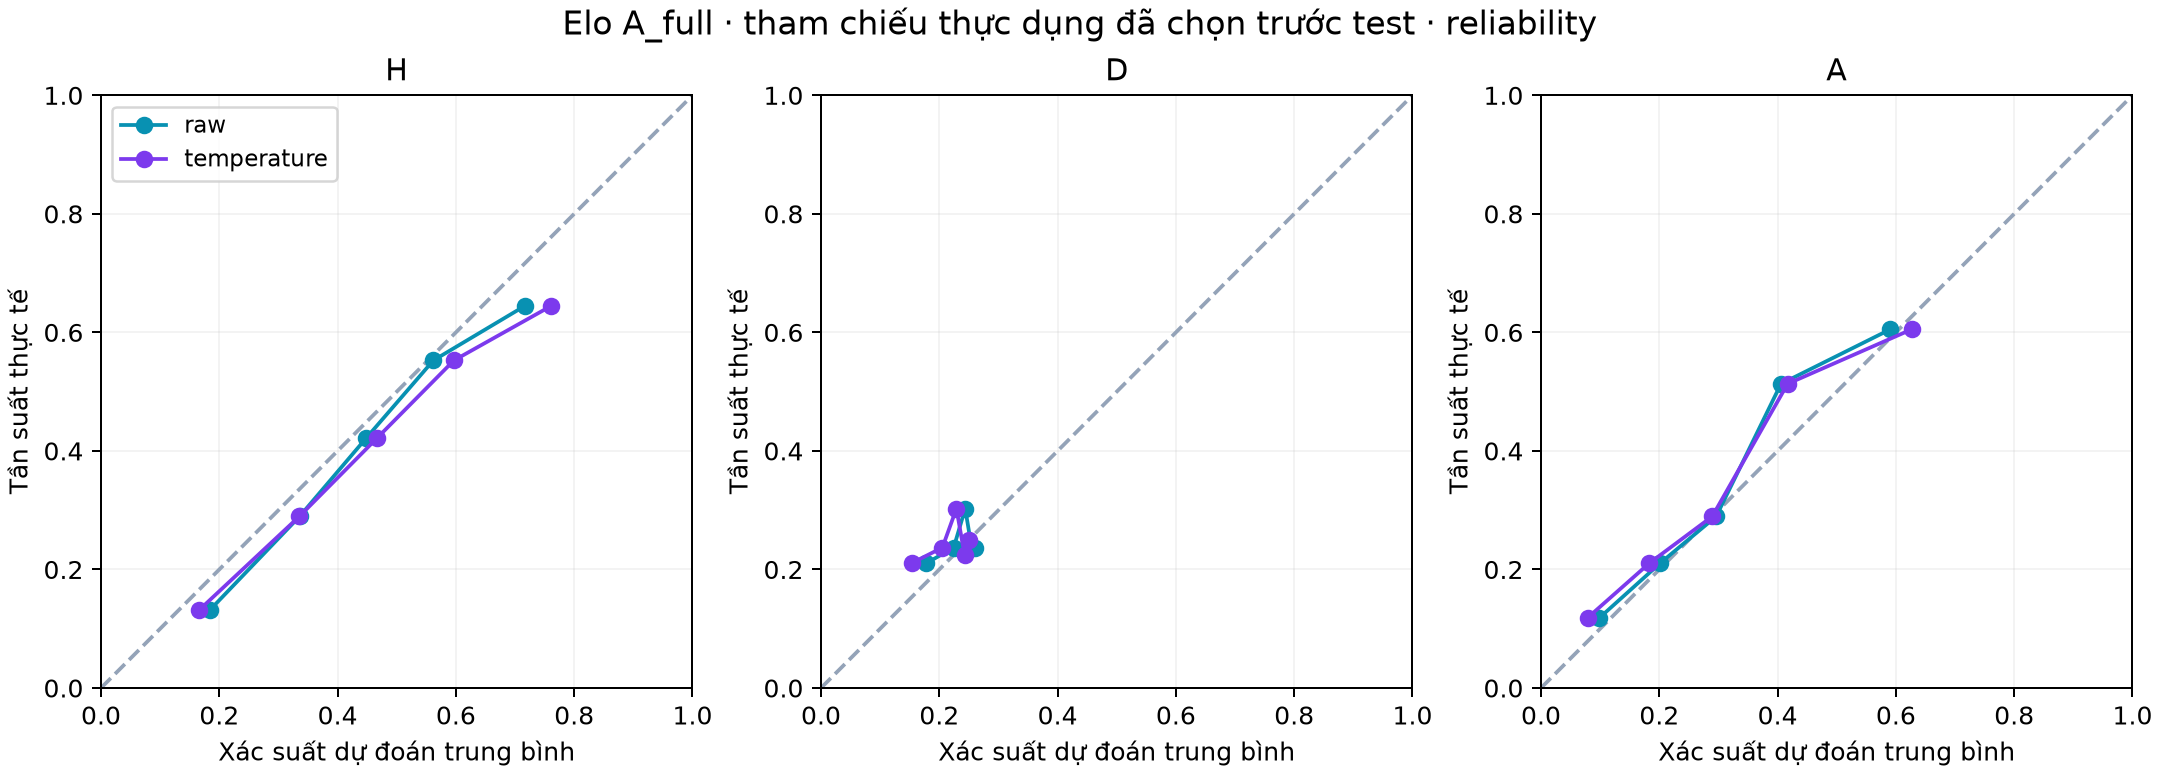

In [9]:
r=data['result']['metrics']['full__elo::raw']
display(pd.DataFrame(r['confusion_matrix_rows_true_cols_pred_HDA'],index=['Thật H','Thật D','Thật A'],columns=['Dự đoán H','Dự đoán D','Dự đoán A']))
display(pd.DataFrame(r['per_class']).T)
display(Image(filename=str(ROOT/'reports/final_test_v1/reference_reliability.png')))

## 8. Xem một trận trong archive

Đây là dự đoán lịch sử đã lưu, không phải dự báo trực tiếp. Có thể đổi chỉ số `match_index` để xem trận khác mà không fit lại.

In [10]:
match_index = 0
catalog=pd.DataFrame(data['matches'])
match=catalog.iloc[match_index]
display(match.to_frame('Giá trị'))
chosen=pred[pred.match_id.eq(match.match_id)&pred.model.eq('full__elo')]
display(chosen[['variant','p_H','p_D','p_A','predicted_label']])

,Giá trị
match_id,epl_3b0830adf0b4c8192eaf
match_date,2024-08-16
home_team,Man United
away_team,Fulham
home_goals,1
away_goals,0
result,H


,variant,p_H,p_D,p_A,predicted_label
0,raw,0.5579128082121598,0.23844381502516415,0.20364337676267608,H
380,temperature,0.5925161190752131,0.22223139182245943,0.18525248910232753,H


## 9. Kết luận và tái lập

Elo là baseline mạnh; P/F chưa có bằng chứng cải thiện chắc chắn theo protocol; calibration fit một mùa không bảo đảm tốt hơn mùa kế tiếp. Không suy rộng thành “cầu thủ không quan trọng” hoặc “calibration luôn có hại”.

Notebook này tái lập **kết quả từ artifact**, không thay cho việc chạy lại thu thập, chuẩn hóa và huấn luyện từ raw. Xem `docs/reproducibility.vi.md` để phân biệt các mức tái lập. Demo mở ở `demo/index.html`. Dữ liệu, mô hình và mã scoring đã khóa không được sửa để tìm điểm test tốt hơn.